# Аналіз синтетичного журналу ланцюга поставок

Набір побудовано за структурою DataCo Smart Supply Chain: 25 000 передач,
2 376 партій, 9 000 аномалій. Ноутбук перевіряє розмір, пропуски, баланс класів,
розподіли, кореляції, часову структуру та схему розбиття.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("..")
from ml.features import engineer

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
raw = pd.read_csv("../data/events.csv")
df = engineer(raw)
print("shape:", df.shape)
print("batches:", df.batch_id.nunique())
print("anomalies:", int(df.is_anomaly.sum()))
df.head(3)


shape: (25000, 47)
batches: 2376
anomalies: 9000


,event_id,timestamp,batch_id,product_id,product_category,cold_chain,serial,event_type,route_step,from_id,...,quantity_delta,quantity_ratio,temp_deviation,hour,weekday,is_night,scan_distance_km,license_status_code,detour_ratio,scan_velocity
0,1,2026-05-21 14:49:27.561436840+00:00,1,INSULIN-100,insulin,1,100001,ship,1,M01,...,0.0,1.0,0.34,14,3,0,563.849172,0,2.999908,0.133333
1,2,2026-05-21 20:13:47.159833468+00:00,1,INSULIN-100,insulin,1,100001,receive,1,M01,...,0.0,1.0,1.18,20,3,0,0.000000,0,1.500023,0.500000
2,3,2026-05-22 02:11:42.702582145+00:00,1,INSULIN-100,insulin,1,100001,scan,1,M01,...,0.0,1.0,1.42,2,4,1,0.000000,0,1.000000,1.000000


## Пропуски

Пропуски є лише в трьох числових ознаках; їх частка не перевищує 1,7 %.

In [2]:
missing = df[["temperature_c", "transit_hours", "quantity_received"]].isna().mean() * 100
missing.round(2).to_frame("missing_%")


,missing_%
temperature_c,1.63
transit_hours,0.81
quantity_received,0.92


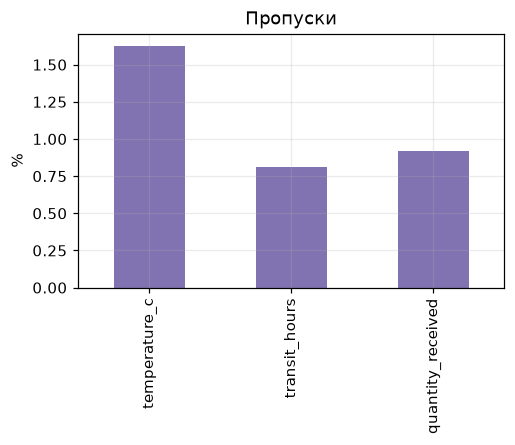

In [3]:
missing.plot.bar(color="#8172b2", figsize=(5, 3), ylabel="%", title="Пропуски")
plt.show()


## Баланс класів і типи аномалій

In [4]:
counts = df.is_anomaly.value_counts().sort_index()
print(counts.to_string())
print("anomaly rate: %.3f" % (counts[1] / counts.sum()))
types = df[df.is_anomaly == 1].anomaly_name.value_counts()
types.to_frame("count")


is_anomaly
0    16000
1     9000
anomaly rate: 0.360


,count
anomaly_name,
route_deviation,2520
clone_scan,1980
time_anomaly,1980
quantity_mismatch,1530
license_anomaly,990


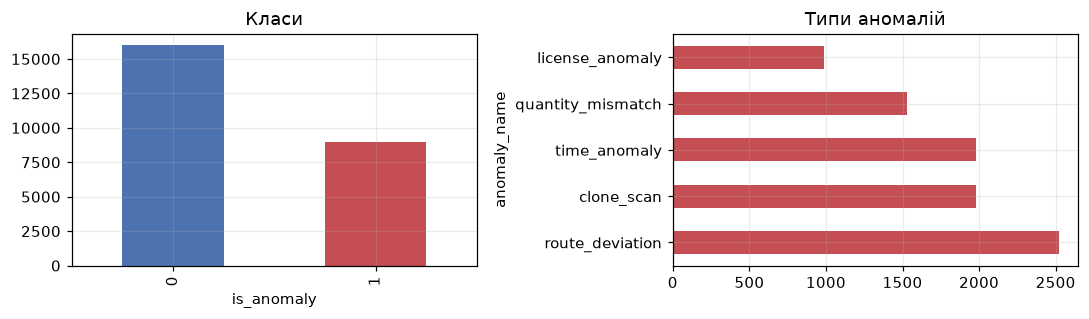

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
counts.plot.bar(ax=axes[0], color=["#4c72b0", "#c44e52"], title="Класи")
types.plot.barh(ax=axes[1], color="#c44e52", title="Типи аномалій")
plt.tight_layout()
plt.show()


## Розподіли ключових ознак

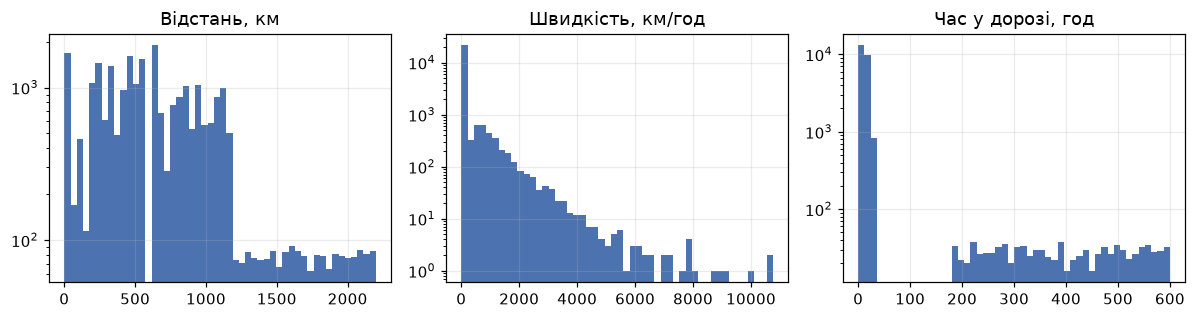

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, column, title in zip(
    axes,
    ["distance_km", "speed_kmh", "transit_hours"],
    ["Відстань, км", "Швидкість, км/год", "Час у дорозі, год"],
):
    values = df[column].dropna()
    ax.hist(values, bins=50, color="#4c72b0")
    ax.set_yscale("log")
    ax.set_title(title)
plt.tight_layout()
plt.show()


## Кореляційна матриця

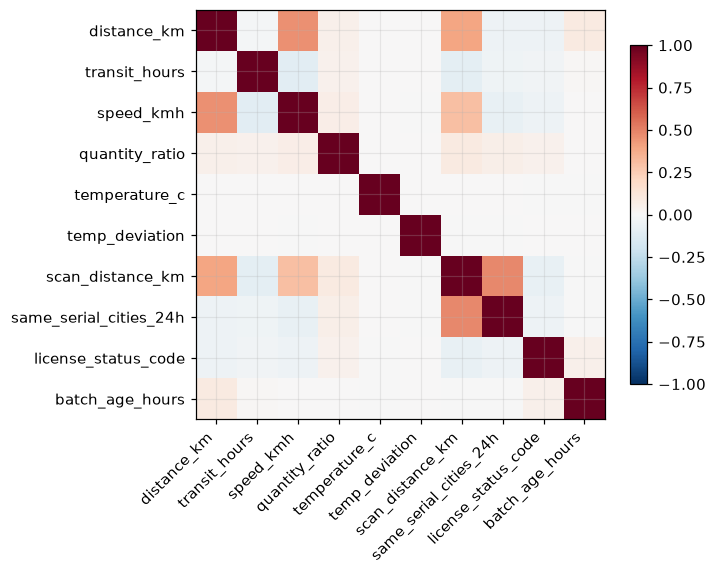

In [7]:
columns = [
    "distance_km", "transit_hours", "speed_kmh", "quantity_ratio",
    "temperature_c", "temp_deviation", "scan_distance_km",
    "same_serial_cities_24h", "license_status_code", "batch_age_hours",
]
corr = df[columns].corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(columns)), columns, rotation=45, ha="right")
ax.set_yticks(range(len(columns)), columns)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()


## Часова структура

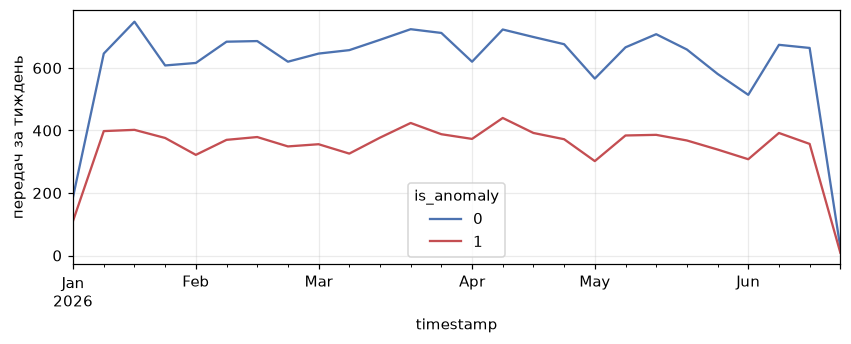

In [8]:
weekly = (
    df.set_index("timestamp").groupby([pd.Grouper(freq="W"), "is_anomaly"]).size().unstack(fill_value=0)
)
weekly.plot(figsize=(9, 3), color=["#4c72b0", "#c44e52"], ylabel="передач за тиждень")
plt.show()


## Викиди

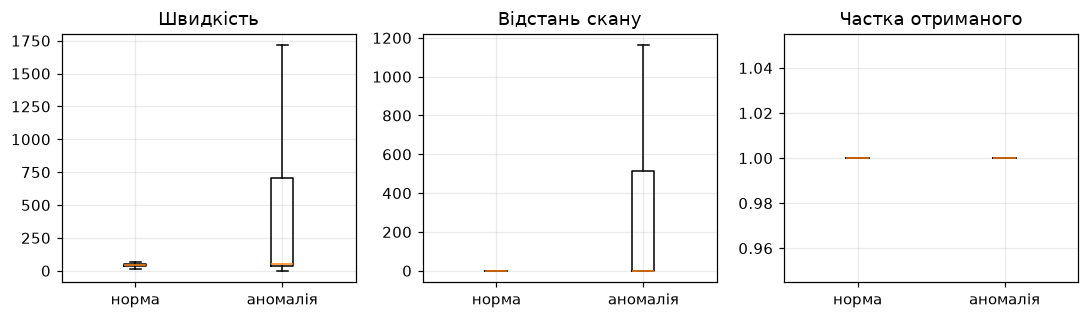

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, column, title in zip(
    axes,
    ["speed_kmh", "scan_distance_km", "quantity_ratio"],
    ["Швидкість", "Відстань скану", "Частка отриманого"],
):
    data = [df[df.is_anomaly == 0][column].dropna(), df[df.is_anomaly == 1][column].dropna()]
    ax.boxplot(data, tick_labels=["норма", "аномалія"], showfliers=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()


## Розбиття без витоку

In [10]:
starts = df.groupby("batch_id")["timestamp"].min().sort_values()
ids = starts.index.to_numpy()
n = len(ids)
train_ids = set(ids[: int(n * 0.7)])
val_ids = set(ids[int(n * 0.7) : int(n * 0.85)])
test_ids = set(ids[int(n * 0.85) :])
parts = {
    "train": df[df.batch_id.isin(train_ids)],
    "val": df[df.batch_id.isin(val_ids)],
    "test": df[df.batch_id.isin(test_ids)],
}
for name, part in parts.items():
    print("%-5s rows=%5d batches=%4d anomaly=%.3f" % (
        name, len(part), part.batch_id.nunique(), part.is_anomaly.mean()))
print("train until", parts["train"].timestamp.max())
print("test from  ", parts["test"].timestamp.min())
assert not (set(parts["train"].batch_id) & set(parts["test"].batch_id))
print("no batch overlaps:", True)


train rows=17443 batches=1663 anomaly=0.360
val   rows= 3762 batches= 356 anomaly=0.356
test  rows= 3795 batches= 357 anomaly=0.364
train until 2026-05-01 20:23:54.792297783+00:00
test from   2026-05-24 03:31:17.066804877+00:00
no batch overlaps: True


## Висновки

1. Клас аномалій становить 36 % — це синтетичний дисбаланс, обраний для перевірки
   моделей; у реальному журналі частка буде нижчою, тому поріг і метрики треба
   перераховувати на реальних даних.
2. Пропуски є лише в трьох ознаках (до 1,63 %), їх закриває медіанна імпутація
   всередині конвеєра, а не ручна правка CSV.
3. Швидкість і відстань сканування розділяють класи найкраще; кореляція між ними
   помірна, тому обидві ознаки залишено.
4. Часовий ряд не має сезонності, але партії розподілені нерівномірно; розбиття
   виконано за партіями і за часом, щоб одна партія не потрапила у дві вибірки.
5. Ознаки `anomaly_type`, `is_anomaly` та ідентифікатори у навчання не входять.
